# Experiment 4: Classification using Python
## Decision Tree and Naïve Bayes — Airline Passenger Satisfaction
**Aim:** Predict whether a passenger is satisfied or neutral/dissatisfied using the supplied training and test files.

Run the cells in order. On Colab, upload both CSV files when prompted. On Windows Jupyter, edit `DATA_DIR` if necessary. The notebook selects the tree depth using only `train.csv`; `test.csv` is reserved for final evaluation. Screenshot numbers appear at the relevant cells. Runtime varies; the depth search may take several minutes.

In [ ]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
CLASS_NAMES = ['neutral or dissatisfied', 'satisfied']
print('Libraries imported successfully.')

Libraries imported successfully.


## Load both files
**Colab:** choose both `train.csv` and `test.csv` together. **Windows Jupyter:** the path below matches the folder you provided; change it if needed.

In [ ]:
import os
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import files
    print('Select BOTH train.csv and test.csv in the file picker.')
    uploaded = files.upload()

    # Resolve automatic duplication suffixes (e.g. train (1).csv, train (2).csv)
    actual_train = None
    actual_test = None
    for key in uploaded.keys():
        if 'train' in key.lower() and key.endswith('.csv'):
            actual_train = key
        elif 'test' in key.lower() and key.endswith('.csv'):
            actual_test = key

    if actual_train and actual_train != 'train.csv':
        if os.path.exists('train.csv'):
            os.remove('train.csv')
        os.rename(actual_train, 'train.csv')

    if actual_test and actual_test != 'test.csv':
        if os.path.exists('test.csv'):
            os.remove('test.csv')
        os.rename(actual_test, 'test.csv')

    if not os.path.exists('train.csv') or not os.path.exists('test.csv'):
        raise FileNotFoundError('Upload both train.csv and test.csv together. Run this cell again.')
    train_path, test_path = Path('train.csv'), Path('test.csv')
else:
    DATA_DIR = Path(r'C:\Users\Admin\Downloads\archive (1)')
    train_path, test_path = DATA_DIR / 'train.csv', DATA_DIR / 'test.csv'
    if not train_path.is_file() or not test_path.is_file():
        raise FileNotFoundError(f'Could not find both CSV files in {DATA_DIR}. Edit DATA_DIR above.')

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
print('Training data:', train_df.shape)
print('Test data:    ', test_df.shape)
display(train_df.head())

Select BOTH train.csv and test.csv in the file picker.


Saving test.csv to test (2).csv
Saving train.csv to train (3).csv
Training data: (103904, 25)
Test data:     (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


## Prepare the data — Screenshot 1
Each pipeline learns medians and category encoding from its own training data. Cross-validation fits these steps separately in each fold.

In [ ]:
target = 'satisfaction'
label_map = {'neutral or dissatisfied': 0, 'satisfied': 1}
for name, frame in [('train.csv', train_df), ('test.csv', test_df)]:
    if target not in frame.columns:
        raise ValueError(f'{name} does not contain the satisfaction column.')
    unknown = frame[target].isna() | ~frame[target].isin(label_map)
    if unknown.any():
        raise ValueError(f'{name} has {unknown.sum()} missing or unexpected satisfaction values.')

y_train = train_df[target].map(label_map).astype(int)
y_test = test_df[target].map(label_map).astype(int)
X_train = train_df.drop(columns=[target, 'Unnamed: 0', 'id'], errors='ignore').copy()
X_test = test_df.drop(columns=[target, 'Unnamed: 0', 'id'], errors='ignore').copy()
if set(X_train.columns) != set(X_test.columns):
    raise ValueError(f'Feature columns differ. Missing in test: {set(X_train.columns)-set(X_test.columns)}; extra in test: {set(X_test.columns)-set(X_train.columns)}')
X_test = X_test[X_train.columns]
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_train.columns.difference(cat_cols, sort=False).tolist()
# Use dense output, compatible with GaussianNB and multiple scikit-learn versions.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), num_cols),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('encoder', encoder)]), cat_cols)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Training records:', len(X_train), '| Test records:', len(X_test))
print('Original feature columns:', X_train.shape[1])
print('Missing feature values: train =', X_train.isna().sum().sum(), ', test =', X_test.isna().sum().sum())
print('Training class balance (%):')
print((y_train.value_counts(normalize=True).sort_index()*100).round(1).rename({0: CLASS_NAMES[0], 1: CLASS_NAMES[1]}).to_string())
print('Preprocessing will be fitted inside each training fold.')

Training records: 103904 | Test records: 25976
Original feature columns: 22
Missing feature values: train = 310 , test = 83
Training class balance (%):
satisfaction
neutral or dissatisfied    56.7
satisfied                  43.3
Preprocessing will be fitted inside each training fold.


## Select Decision Tree depth — Screenshot 2
The validation scores are for tuning, not independent final performance. This cell can take several minutes.

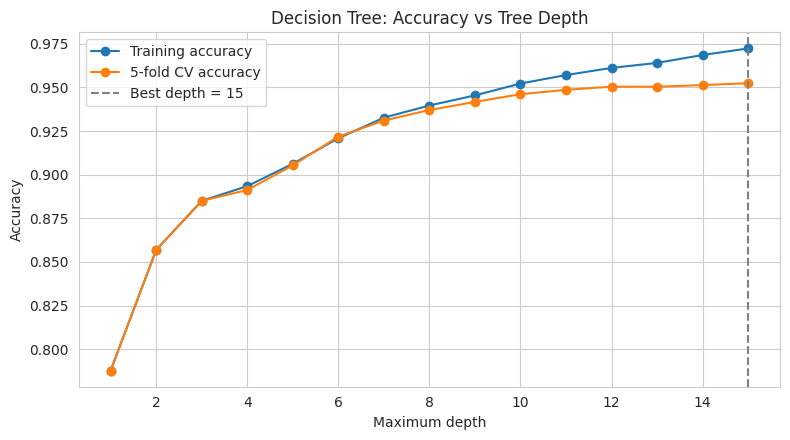

Best depth: 15 | CV accuracy: 0.9524 ± 0.0015


In [ ]:
depths = list(range(1, 16))
train_acc, cv_acc, cv_std = [], [], []
for depth in depths:
    pipe = Pipeline([('preprocess', clone(preprocessor)), ('model', DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42))])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    pipe.fit(X_train, y_train)
    train_acc.append(pipe.score(X_train, y_train))
    cv_acc.append(scores.mean())
    cv_std.append(scores.std())
best_idx = int(np.argmax(cv_acc))
best_depth = depths[best_idx]
plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_acc, marker='o', label='Training accuracy')
plt.plot(depths, cv_acc, marker='o', label='5-fold CV accuracy')
plt.axvline(best_depth, color='grey', linestyle='--', label=f'Best depth = {best_depth}')
plt.title('Decision Tree: Accuracy vs Tree Depth')
plt.xlabel('Maximum depth'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout(); plt.show()
print(f'Best depth: {best_depth} | CV accuracy: {cv_acc[best_idx]:.4f} ± {cv_std[best_idx]:.4f}')

## Train and display the Decision Tree — Screenshot 3

Depth: 15 | Leaves: 1248 | Training time (including preprocessing): 1.07 s


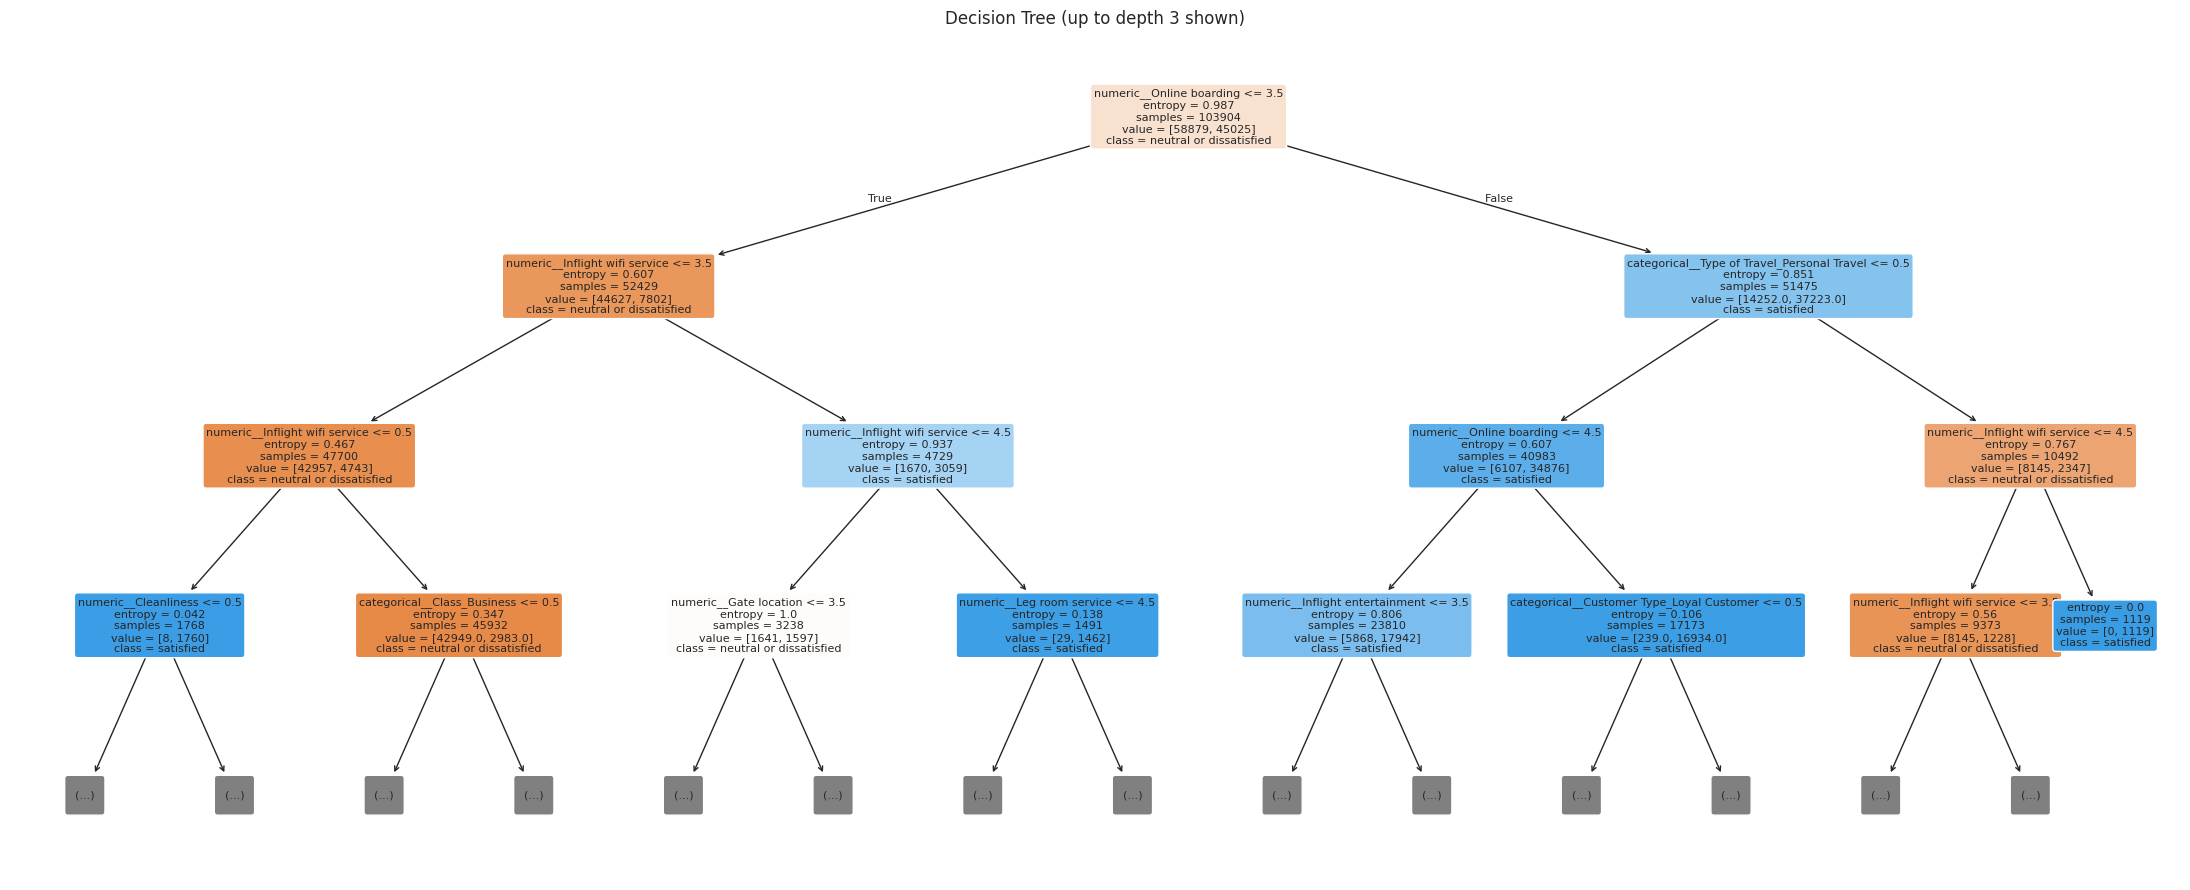

In [ ]:
dt = Pipeline([('preprocess', clone(preprocessor)), ('model', DecisionTreeClassifier(criterion='entropy', max_depth=best_depth, random_state=42))])
t0 = time.perf_counter(); dt.fit(X_train, y_train); dt_time = time.perf_counter() - t0
tree = dt.named_steps['model']
feature_names = dt.named_steps['preprocess'].get_feature_names_out()
print(f'Depth: {tree.get_depth()} | Leaves: {tree.get_n_leaves()} | Training time (including preprocessing): {dt_time:.2f} s')
plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=feature_names, class_names=CLASS_NAMES, filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title('Decision Tree (up to depth 3 shown)'); plt.tight_layout(); plt.show()

## Top features — Screenshot 4

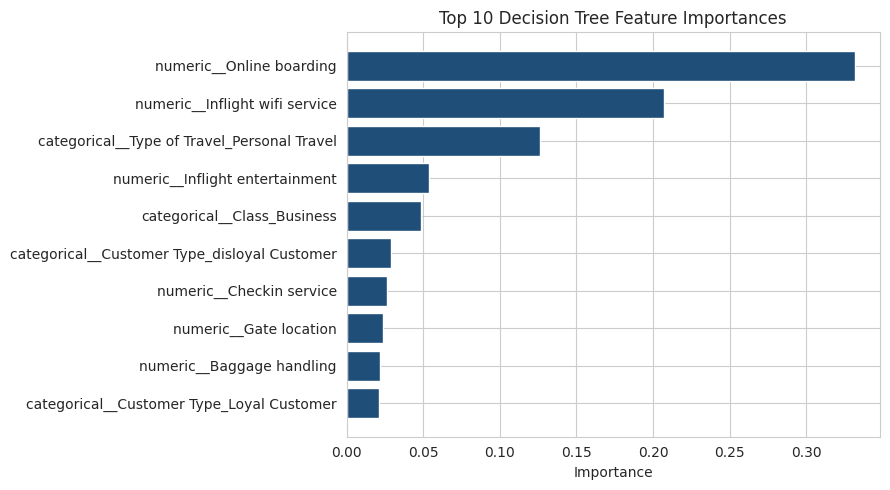

In [ ]:
imp = pd.Series(tree.feature_importances_, index=feature_names).nlargest(10).sort_values()
plt.figure(figsize=(9, 5)); plt.barh(imp.index, imp.values, color='#1F4E79')
plt.title('Top 10 Decision Tree Feature Importances'); plt.xlabel('Importance'); plt.tight_layout(); plt.show()

## Train Gaussian Naïve Bayes

In [ ]:
nb = Pipeline([('preprocess', clone(preprocessor)), ('model', GaussianNB())])
t0 = time.perf_counter(); nb.fit(X_train, y_train); nb_time = time.perf_counter() - t0
print(f'Naïve Bayes training time (including preprocessing): {nb_time:.2f} s')
for label, p in zip(CLASS_NAMES, nb.named_steps['model'].class_prior_):
    print(f'{label}: {p:.3f}')

Naïve Bayes training time (including preprocessing): 0.45 s
neutral or dissatisfied: 0.567
satisfied: 0.433


## Test-set evaluation — Screenshot 5
Capture the reports and both confusion matrices. If they do not fit in one image, take two images.

DECISION TREE
                         precision    recall  f1-score   support

neutral or dissatisfied      0.951     0.967     0.959     14573
              satisfied      0.957     0.936     0.946     11403

               accuracy                          0.953     25976
              macro avg      0.954     0.952     0.953     25976
           weighted avg      0.954     0.953     0.953     25976

NAÏVE BAYES
                         precision    recall  f1-score   support

neutral or dissatisfied      0.856     0.869     0.862     14573
              satisfied      0.829     0.813     0.821     11403

               accuracy                          0.844     25976
              macro avg      0.842     0.841     0.842     25976
           weighted avg      0.844     0.844     0.844     25976



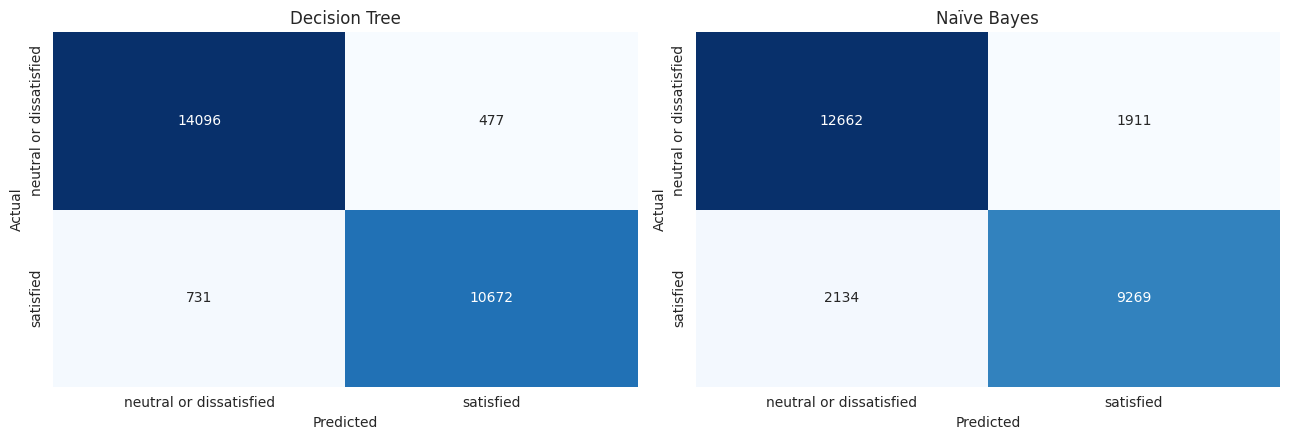

In [ ]:
dt_pred, nb_pred = dt.predict(X_test), nb.predict(X_test)
for name, pred in [('DECISION TREE', dt_pred), ('NAÏVE BAYES', nb_pred)]:
    print(name)
    print(classification_report(y_test, pred, labels=[0, 1], target_names=CLASS_NAMES, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, pred, name in zip(axes, [dt_pred, nb_pred], ['Decision Tree', 'Naïve Bayes']):
    sns.heatmap(confusion_matrix(y_test, pred, labels=[0,1]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## ROC curves — Screenshot 6

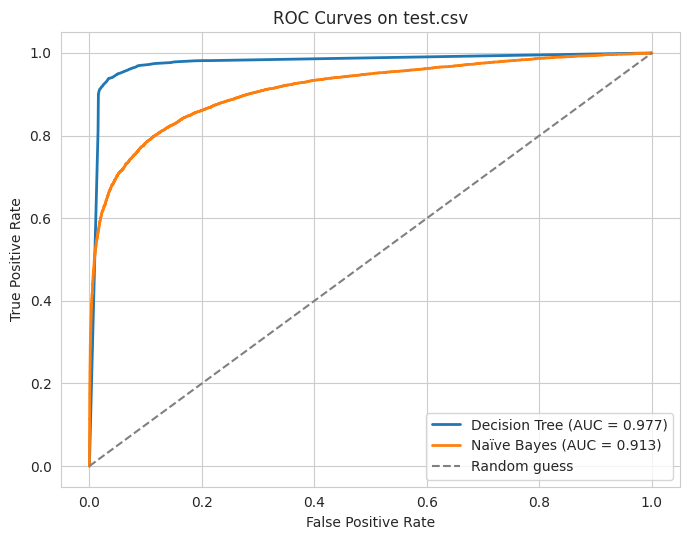

In [ ]:
dt_prob, nb_prob = dt.predict_proba(X_test)[:, 1], nb.predict_proba(X_test)[:, 1]
plt.figure(figsize=(7, 5.5))
for prob, name in [(dt_prob, 'Decision Tree'), (nb_prob, 'Naïve Bayes')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], '--', color='grey', label='Random guess')
plt.title('ROC Curves on test.csv'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

## Compare classifiers — Screenshot 7
Precision, recall and F1 are for **satisfied**. The tree CV score was also used to select depth; compare final performance using the independent test metrics. Training times include preprocessing.

Test metrics: positive class = satisfied


,Accuracy,Precision,Recall,F1-score,AUC,5-fold CV accuracy (mean),5-fold CV accuracy (std),Training time (s)
Decision Tree,0.9535,0.9572,0.9359,0.9464,0.9768,0.9524,0.0015,1.0296
Naïve Bayes,0.8443,0.8291,0.8129,0.8209,0.9135,0.8489,0.0032,0.4488


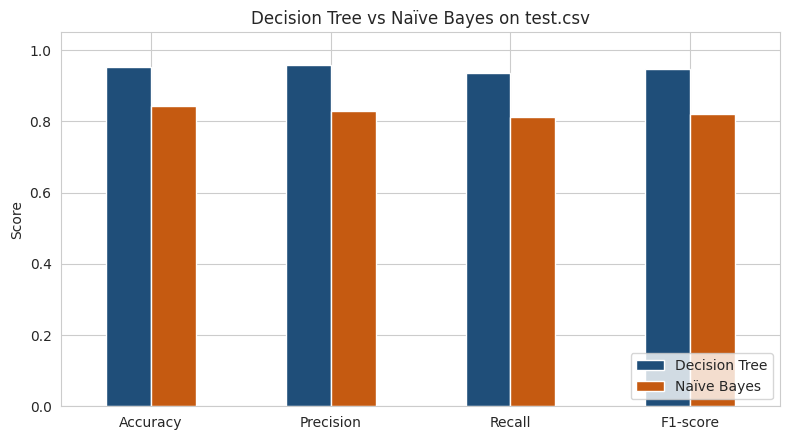

In [ ]:
nb_cv = cross_val_score(nb, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
rows = {}
for name, pred, prob, secs, cv_mean, cv_sd in [
    ('Decision Tree', dt_pred, dt_prob, dt_time, cv_acc[best_idx], cv_std[best_idx]),
    ('Naïve Bayes', nb_pred, nb_prob, nb_time, nb_cv.mean(), nb_cv.std())]:
    rows[name] = {'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
        'AUC': roc_auc_score(y_test, prob),
        '5-fold CV accuracy (mean)': cv_mean, '5-fold CV accuracy (std)': cv_sd,
        'Training time (s)': secs}
comparison = pd.DataFrame(rows).T
print('Test metrics: positive class = satisfied')
display(comparison.round(4))
comparison[['Accuracy', 'Precision', 'Recall', 'F1-score']].T.plot(kind='bar', figsize=(8, 4.5), color=['#1F4E79', '#C55A11'])
plt.title('Decision Tree vs Naïve Bayes on test.csv'); plt.ylabel('Score'); plt.ylim(0, 1.05)
plt.xticks(rotation=0); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

## Result
Both classification algorithms were implemented. Record the actual test accuracy, precision, recall, F1-score and AUC from the comparison table, then state which model performed better for the chosen metric. Gaussian Naïve Bayes assumes features follow a Gaussian distribution within each class; this is an approximation for binary encoded features.